In [19]:
%matplotlib notebook
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import time
import scipy.io as scio
import math
import h5py
from matplotlib.colors import ListedColormap
import matplotlib.colors as colors
plt.rc('font',family='serif', size=14)

def run(step1, step2, L, W, H, D1, D2):
    steps = random.randint(step1, step2)
    xyz = []
    x0 = random.randint(1, L)
    y0 = random.randint(1, W)
    z0 = random.randint(D1, D2)

    cur1 = [x0, y0, z0]
    cur2 = [x0+1, y0, z0]
    cur3 = [x0, y0+1, z0]
    cur4 = [x0+1, y0+1, z0]
    cur5 = [x0, y0, z0+1]
    cur6 = [x0+1, y0, z0+1]
    cur7 = [x0, y0+1, z0+1]
    cur8 = [x0+1, y0+1, z0+1]
    xyz.extend((cur1, cur2, cur3, cur4, cur5, cur6, cur7, cur8))

    for _ in range(steps):
        axis = random.randint(0, 2)
        stride = random.choice([-2, 2])
        cur1[axis] += stride
        cur2[axis] += stride
        cur3[axis] += stride
        cur4[axis] += stride
        cur5[axis] += stride
        cur6[axis] += stride
        cur7[axis] += stride
        cur8[axis] += stride

        if cur1[0] <= 1:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = 1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = 2
        if cur8[0] >= L:
            cur1[0] = cur3[0] = cur5[0]= cur7[0] = L-1
            cur2[0] = cur4[0] = cur6[0]= cur8[0] = L

        if cur1[1] <= 1:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = 1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = 2
        if cur8[1] >= W:
            cur1[1] = cur2[1] = cur5[1]= cur6[1] = W-1
            cur3[1] = cur4[1] = cur7[1]= cur8[1] = W

        if cur1[2] <= D1:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D1+1
        if cur8[2] >= D2:
            cur1[2] = cur2[2] = cur3[2]= cur4[2] = D2-1
            cur5[2] = cur6[2] = cur7[2]= cur8[2] = D2

        xyz.extend((cur1[:], cur2[:], cur3[:], cur4[:], cur5[:], cur6[:], cur7[:], cur8[:]))
    return xyz

# For Irregular(Random) model
def random_walk(path, n, step1, step2, L, W, H, D1, D2):
    if n == 1:
        model1 = run(step1, step2, L, W, H, D1, D2)
        xyz = model1
    if n == 2:
        step1 = step1/2
        step2 = step2/2
        model1 = run(step1, step2, L, W, H, D1, D2)
        model2 = run(step1, step2, L, W, H, D1, D2)
        xyz = model1 + model2
    
    for i in range(len(xyz)):
        xyz[i].append(1) 
    np.savetxt(path, xyz, fmt="%d", delimiter='\t')

L = 32
W = 32
H = 16
D1 = 1
D2 = 16
step1 = 60
step2 = 80
number = 3000
syn_number = 200
path = r"./model/tra&val/"

start = time.time()
for i in range(0, number):
    model_path = path+ 'model{}.dat'.format(i)
    n = random.randint(1, 2)
    random_walk(model_path, n, step1, step2, L, W, H, D1, D2)
end = time.time()
times = end - start
print('Cost times : %d s' %times)

# For Regular Model(Rectangular Prism)
def save_regular_models(model, path): #Convert a 3D Boolean prism model into a coordinate list and save it as a text file.
    coords = np.argwhere(model) + 1 #This function from NumPy finds only the locations where the model is True.,#+ 1   # convert to 1-based indices

    data = np.hstack((coords, np.ones((coords.shape[0], 1), dtype=int))) #Add a Column of Ones (Property Value)(Density)
    np.savetxt(path, data, fmt="%d", delimiter='\t')

# --- Type I: Rectangular Prism(Regular Model) ---
def run1(path):
    
    L, W, H = np.indices((32, 32, 16)) # This line creates 3 separate 3D matrices representing grid coordinates using NumPy.    
    lowerx = np.random.randint(3, 23) #Generates a random integer between 3 and 22, #This is the starting X index of the prism
    upperx = lowerx + 8 #The prism width in X-direction is: width = 8 cells
    lowery = np.random.randint(3, 25) #Generates a random Y start location,#Range: 3 to 24
    
    uppery = lowery + 6 #The prism width in Y-direction is:width = 6 cells
    h0 = np.random.randint(1, 9) #Chooses a random depth start
    h1 = h0 + 8 #The vertical thickness (height in Z-direction) is: 8 cells
    model = (L < upperx) & (L >= lowerx) & (W < uppery) & (W >= lowery) & (H < h1) & (H >= h0)
    save_regular_models(model, path)
    return model

Cost times : 4 s


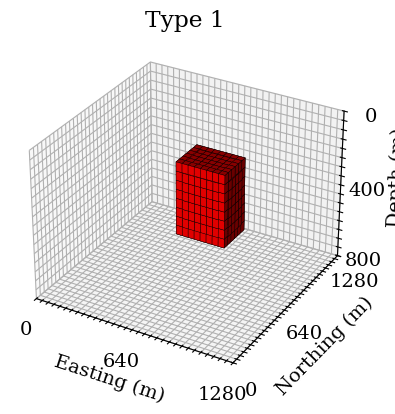

In [20]:
# ============================================================
for i in range(syn_number):
    path = r'./model/syn/model{}.dat'
    run1(path.format(i))
models = []
for i, func in enumerate([run1], start=1):
    model = func(path)
    models.append((f"Type {i}", model))

%matplotlib inline
fig = plt.figure(figsize=(20, 10))
for i, (title, model) in enumerate(models, start=1):
    ax = fig.add_subplot(2, 3, i, projection='3d')
    ax.voxels(model, facecolors='red', edgecolors='k', linewidth=0.3)
    ax.set_title(title)
    plt.xticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
    ax.set_xlabel('Easting (m)')
    plt.yticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
    ax.set_ylabel('Northing (m)')
    ax.set_zticks(np.arange(0, 17, 1))
    ax.set_zticklabels(['0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '400', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '800'])
    ax.set_zlabel('Depth (m)')
    ax.invert_zaxis()
    
plt.show()

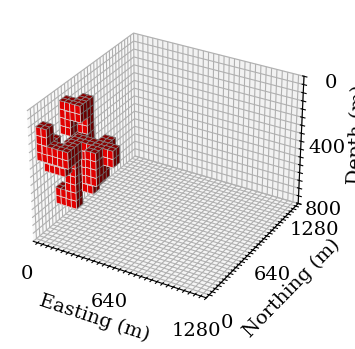

In [21]:
path = r'./model/tra&val/model{}.dat'.format(200)
data = pd.read_table(path, sep = '\t', header=None, engine='python')
model = np.zeros((32, 32, 16))
for i in range(len(data)):
    index = data.iloc[i]
    x = index[0] - 1
    y = index[1] - 1
    z = index[2] - 1
    model[x][y][z] = index[3]
    
model = model > 0
fig = plt.figure(figsize = (8, 4))
ax = fig.add_subplot(111, projection='3d')
ax.voxels(model, facecolors='r', edgecolors='w', linewidth=0.5)
plt.xticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_xlabel('Easting (m)')
plt.yticks(np.arange(0, 33, 1), ('0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '640', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '1280'))
ax.set_ylabel('Northing (m)')
ax.set_zticks(np.arange(0, 17, 1))
ax.set_zticklabels(['0', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '400', ' ', ' ', ' ', ' ', ' ', ' ', ' ', '800'])
ax.set_zlabel('Depth (m)')
ax.invert_zaxis()
plt.show()